<a href="https://colab.research.google.com/github/antoine-bourgois/MIA_2026_UE16_NLP/blob/main/code/3_Plongement_Vectoriel_Documents.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## TP 3 : Plongement Vectoriel de Documents - Approche Sac de mots (Bag of words)

- Chargement dataset
- Tokenisation
- Pré-traitement
- Représentation document sac de mots (BoW)
- Normalisation en fréquences
- TF-IDF
- Similarité cosinus entre documents
- Réduction de dimension
- Clustering

### Installation des librairies Python utiles pour le TP

In [ ]:
!pip install tqdm jupyter ipywidgets datasets pyarrow huggingface_hub pandas matplotlib numpy scipy scikit-learn umap-learn plotly spacy --quiet
! python -m spacy download fr_core_news_sm --quiet

In [ ]:
from tqdm.auto import tqdm
from collections import Counter

# Example Basique

In [ ]:
import spacy
from tqdm import tqdm

nlp = spacy.load("fr_core_news_sm", exclude=["parser", "ner"])

def get_tokens(
    data,
    remove_punctuation=True,
    remove_stop_words=True,
    lowercase=True,
    lemmatize=True,
    batch_size=16,
    n_process=1,
):
    def extract(doc):
        tokens = []
        for token in doc:
            if token.is_space:
                continue
            if remove_punctuation and token.is_punct:
                continue
            if remove_stop_words and token.is_stop:
                continue

            word = token.lemma_ if lemmatize else token.text
            if lowercase:
                word = word.lower()
            tokens.append(word)

        return tokens

    if isinstance(data, str):
        return extract(nlp(data))

    titles = list(data)
    texts = (data[t]["text"] for t in titles)

    try:
        docs = nlp.pipe(
            texts,
            batch_size=batch_size,
            n_process=n_process
        )

        for title, doc in tqdm(zip(titles, docs), total=len(titles)):
            data[title]["tokens"] = extract(doc)

    finally:
        # Release references to the processing iterator
        if "docs" in locals():
            del docs

    return data

In [ ]:
documents = {
    "Nvidia" :
        {"text" : "Nvidia est une entreprise spécialisée dans la conception de processeurs graphiques (GPU) et de puces électroniques. Ses technologies sont utilisées dans les jeux vidéo, l'intelligence artificielle et les centres de données."
         },
    "Amazon" :
        {"text" : "Amazon est une entreprise spécialisée dans le commerce en ligne, la vente de produits et les services de livraison. Elle propose également des services de cloud computing grâce à sa plateforme Amazon Web Services (AWS)."
         },
    "Picard" :
        {"text" : "Picard est une entreprise française spécialisée dans la distribution de produits alimentaires surgelés. Elle propose une large gamme de plats préparés, de légumes, de desserts et de produits à cuisiner."
         },
}

documents = get_tokens(documents)

In [ ]:
for title, doc_dict in documents.items():
    print(title)
    print(doc_dict["text"])
    print(doc_dict["tokens"])
    print()

## Construire la matrice document x sac de mots

In [ ]:
from collections import Counter
import pandas as pd

bow_df = pd.DataFrame.from_dict(
    {
        title: Counter(doc_dict["tokens"])
        for title, doc_dict in documents.items()
    },
    orient="index"
).fillna(0).astype(int)

bow_df = bow_df[bow_df.sum().sort_values(ascending=False).index]

# bow_df = bow_df[bow_df.sum().nlargest(10).index]

bow_df

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 1))

sns.heatmap(
    bow_df,
    annot=True,
    fmt=".0f",          # Display integers
    cmap="Blues",
    linewidths=0.5,
    cbar=False
)

plt.title("Représentation Sacs de Mots (occurrences)")
plt.xlabel("Mots")
plt.ylabel("")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0, ha="right")
plt.tight_layout()
plt.show()

## TF-IDF (Term Frequency – Inverse Document Frequency)
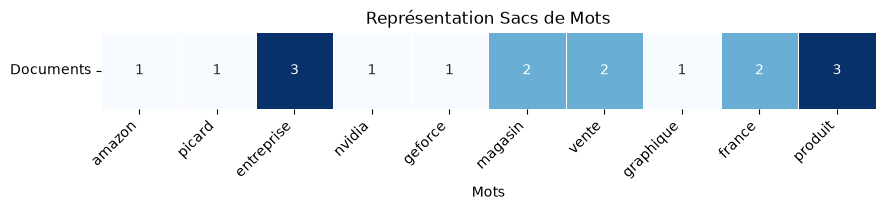

### TF (Term Frequency) : fréquence du terme dans un document

Dans cette étape, nous calculons la fréquence relative de chaque mot dans chaque document.

In [ ]:
tf = bow_df.div(bow_df.sum(axis=1), axis=0)

tf

### IDF (Inverse Document Frequency) : fréquence inverse du document

L'IDF permet de mesurer à quel point un mot est rare ou fréquent dans l'ensemble de notre collection de documents.

In [ ]:
import numpy as np

# Nombre total de documents
N = len(bow_df)

# Nombre de documents contenant chaque mot
df = (bow_df > 0).sum(axis=0)

# Conversion en DataFrame
df = df.to_frame(name="Documents")

df.T

In [ ]:
# Calcul de l'IDF
idf = np.log(N / df["Documents"])

# Conversion en DataFrame
idf = idf.to_frame(name="IDF")

idf.index.name = "Mot"

idf.T

In [ ]:
tfidf_df = tf.mul(idf["IDF"], axis=1)

tfidf_df = tfidf_df.T
tfidf_df

In [ ]:
for column in tfidf_df:
    top = (
        tfidf_df[column]
        .sort_index()
        .sort_values(ascending=False, kind="stable")
        .head(5)
    )
    top = top[top > 0]

    keywords = ", ".join(f"{word} [{score:.3f}]" for word, score in top.items())
    print(f"{column}:")
    print(f"Mots-clés : {keywords}")
    print()

### Utiliser TfidfVectorizer de scikit-learn

Scikit-learn propose une classe appelée `TfidfVectorizer` qui permet de calculer automatiquement les poids TF-IDF à partir d'une collection de documents.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd

# Récupération des tokens de chaque document
texts = [
    doc_dict["tokens"]
    for title, doc_dict in documents.items()
]

vectorizer = TfidfVectorizer(
    analyzer=lambda tokens: tokens
)

In [ ]:
X_tfidf = vectorizer.fit_transform(texts)

In [ ]:
tfidf_sklearn = pd.DataFrame(
    X_tfidf.toarray(),
    index=documents.keys(),
    columns=vectorizer.get_feature_names_out()
)

tfidf_sklearn = tfidf_sklearn.T
tfidf_sklearn

In [ ]:
for column in tfidf_df:
    top = (
        tfidf_df[column]
        .sort_index()
        .sort_values(ascending=False, kind="stable")
        .head(5)
    )
    top = top[top > 0]

    keywords = ", ".join(f"{word} [{score:.3f}]" for word, score in top.items())
    print(f"{column}:")
    print(f"Mots-clés : {keywords}")
    print()

## On retrouve bien les mêmes mots-clés que pour notre implementation manuelle de TF-IDF

## Nous pouvons alors créer deux fonctions pour :

1. Générer la matrice TF-IDF d'un corpus de textes
2. Extraire la liste de mots clés de chaque document

In [ ]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

def compute_tfidf(documents,
                  max_df=1,
                  min_df=1,
                  max_features=100000):
    """
    Compute TF-IDF representations from tokenized documents.

    Parameters
    ----------
    documents : dict
        Dictionary of documents containing a 'tokens' field.

    Returns
    -------
    vectorizer : TfidfVectorizer
        Fitted TF-IDF vectorizer.
    tfidf_df : pd.DataFrame
        TF-IDF matrix indexed by document IDs.
    """

    # Extract tokenized documents
    texts = [doc["tokens"] for doc in documents.values()]

    # Fit TF-IDF model
    vectorizer = TfidfVectorizer(analyzer=lambda x: x,
                                max_df=max_df,
                                 min_df=min_df,
                                 max_features=max_features
                                 )
    X_tfidf = vectorizer.fit_transform(texts)

    # Create DataFrame
    tfidf_df = pd.DataFrame(
        X_tfidf.toarray(),
        index=documents.keys(),
        columns=vectorizer.get_feature_names_out()
    )

    return vectorizer, tfidf_df

def extract_keywords(tfidf_df, top_n=5):
    results = {}

    for doc in tfidf_df.index:
        results[doc] = (
            tfidf_df.loc[doc]
            .sort_values(ascending=False, kind="stable")
            .head(top_n)
            .index.tolist()
        )

    return results

In [ ]:
vectorizer, tfidf_df = compute_tfidf(documents)
keywords = extract_keywords(tfidf_df, top_n=100)

for doc_id in tfidf_df.index.tolist():
    print(doc_id)
    striped_TFIDF_vector = [round(dimension, 4) for dimension in tfidf_df.loc[doc_id].tolist()][:10]
    print(f"Vecteur TF-IDF: {striped_TFIDF_vector + ['...']}")
    print(f"Mots-clés : {keywords[doc_id][:5]}")
    print()

## Nous pouvons reproduire l'expérience sur le contenu complet des pages wikipedia de nos trois entreprises d'exemple.

### Commençons par scraper le contenu des pages wikipedia.

In [ ]:
import re
import requests
from urllib.parse import unquote

HEADERS = {"User-Agent": "company-corpus/0.1 (your-email@example.com)"}
API = "https://fr.wikipedia.org/w/api.php"

urls = {
    "Nvidia": "https://fr.wikipedia.org/wiki/Nvidia",
    "Amazon": "https://fr.wikipedia.org/wiki/Amazon",
    "Picard": "https://fr.wikipedia.org/wiki/Picard_Surgel%C3%A9s",
}

CUT = re.compile(
    r"\n==+ *(Notes et références|Références|Voir aussi|Liens externes|Bibliographie|Notes) *==+",
    re.I,
)

def title_from_url(url):
    return unquote(url.rsplit("/wiki/", 1)[1]).replace("_", " ")

def fetch_text(title):
    params = {
        "action": "query",
        "prop": "extracts",
        "explaintext": 1,
        "redirects": 1,
        "titles": title,
        "format": "json",
        "formatversion": 2,
    }
    r = requests.get(API, params=params, headers=HEADERS, timeout=30)
    r.raise_for_status()
    return r.json()["query"]["pages"][0].get("extract", "")

def clean(text):
    m = CUT.search(text)
    if m:
        text = text[: m.start()]
    text = re.sub(r"\n?==+[^=\n]+==+\n?", "\n", text)
    return re.sub(r"\s+", " ", text).strip()

documents = {
    name: {"text": clean(fetch_text(title_from_url(url)))}
    for name, url in urls.items()
}

documents = get_tokens(documents)

In [ ]:
vectorizer, X_tfidf_df = compute_tfidf(documents)
keywords = extract_keywords(X_tfidf_df, top_n=100)

for doc_id in X_tfidf_df.index.tolist():
    print(doc_id)
    striped_TFIDF_vector = [round(dimension, 4) for dimension in X_tfidf_df.loc[doc_id].tolist()][:10]
    print(f"Vecteur TF-IDF: {striped_TFIDF_vector + ['...']}")
    print(f"Mots-clés : {keywords[doc_id][:8]}")
    print()

### Nous pouvons également concevoir une ébauche de moteur de recherche lexical

In [ ]:
query = """Quelle est l'entreprise la plus similaire à AMD ?
Advanced Micro Devices (AMD) est un fabricant américain de semi-conducteurs, microprocesseurs et cartes graphiques basé à Santa Clara (Californie). La compagnie est fondée le 1er mai 1969 par un groupe d'ingénieurs et de dirigeants de Fairchild Semiconductor. Les cofondateurs d'AMD sont Jerry Sanders, Edwin Turney (en), John Carey, Sven Simonsen, Jack Gifford, Frank Botte, Jim Giles et Larry Stenger. La flèche du logotype de la compagnie dirigée vers la droite symbolise sa croissance dans le « droit chemin » (« the right way »).

En 2006, AMD se situe à la 8e place des 20 plus grands fabricants de semi-conducteurs, derrière Intel, Samsung, Texas Instruments, Toshiba, STMicroelectronics, Renesas et Hynix. Au premier trimestre 2007, la AMD chute à la 18e place de ce classement[7]. Il est par contre le deuxième fournisseur de microprocesseurs pour ordinateur PC à architecture x86, après Intel.
"""

query_tokens = get_tokens(query)

print(query_tokens)

query_vector = vectorizer.transform([query_tokens])

# Extract query keywords and their TF-IDF scores
query_keywords = pd.DataFrame({
    "keyword": vectorizer.get_feature_names_out()[query_vector.indices],
    "tfidf_score": query_vector.data
})

query_keywords = query_keywords.sort_values(
    by="tfidf_score",
    ascending=False
)
print()
print(query_keywords.head(5).to_string(index=False))

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

similarities = cosine_similarity(
    query_vector,
    X_tfidf_df.values
).flatten()

import pandas as pd

results = pd.DataFrame({
    "Document": documents.keys(),
    "Score": similarities
})

results = results.sort_values("Score", ascending=False)

results

## Exercice : Construire un moteur de recherche lexical à partir des pages wikipedia des entreprises côtées en bourse

1. Importer le dataset [`AntoineBourgois/wikipedia-companies`](https://huggingface.co/datasets/AntoineBourgois/wikipedia-companies)
2. Décrire succintement le dataset (nombre de documents, champs de chaque document, longueur des textes)
3. Formater le dataset pour correspondre au format `document` utilisé précédemment
```python
documents = {
    "Nvidia": {
        "text": "...",
    },
    "Amazon": {
        "text": "...",
    }
}
```
4. Tokeniser et pré-traiter le corpus avec la fonction : `documents = get_tokens(documents, n_process=8)`

## 1. Importation Dataset

In [ ]:
from datasets import load_dataset

dataset = load_dataset("AntoineBourgois/wikipedia-companies", split="train")
dataset = list(dataset)
dataset = sorted(dataset, key=lambda doc: len(doc["text"]), reverse=True)

In [ ]:
dataset = dataset[:1000]

In [ ]:
print(f"Documents: {len(dataset):,}")
print(f"Plus long document: {len(dataset[0]["text"])}")

In [ ]:
dataset[-1]

In [ ]:
max_characters = 50000
documents = {doc["title"]: {"qid": doc["qid"],
                            "text": doc["text"][:max_characters]} for doc in dataset}

In [ ]:
documents = get_tokens(documents, n_process=8)

In [ ]:
vectorizer, X_tfidf_df = compute_tfidf(documents,
                                       max_df=0.90,
                                       min_df=3,
                                       max_features=15000)
keywords = extract_keywords(X_tfidf_df, top_n=100)

for doc_id in X_tfidf_df.index.tolist()[:15]:
    # print(doc_id)
    striped_TFIDF_vector = [round(dimension, 4) for dimension in X_tfidf_df.loc[doc_id].tolist()][:10]
    # print(f"Vecteur TF-IDF: {striped_TFIDF_vector + ['...']}")
    # doc_keywords = [word for word in keywords[doc_id] if word.lower() not in doc_id.lower()]
    doc_keywords = keywords[doc_id]
    print(f"{doc_id:<25} : {", ".join(doc_keywords[:8])}")

In [ ]:
X_tfidf_df.shape

In [ ]:
import umap
import pandas as pd
import plotly.express as px

reducer = umap.UMAP(
    n_components=2,
    n_neighbors=10,
    metric="cosine",
    n_jobs=-1,
    # random_state=42,
)

embedding = reducer.fit_transform(X_tfidf_df)

umap_df = pd.DataFrame(
    embedding,
    index=documents.keys(),
    columns=["x", "y"]
)
umap_df["title"] = umap_df.index

fig = px.scatter(
    umap_df,
    x="x",
    y="y",
    hover_name="title",
    title="Document visualization using UMAP",
    labels={"x": "UMAP 1", "y": "UMAP 2"},
    width=1000,
    height=700,
)
fig.update_traces(marker=dict(size=6, opacity=0.7))
fig.show()

In [ ]:
query = """Quelle est l'entreprise la plus similaire à AMD ?
Advanced Micro Devices (AMD) est un fabricant américain de semi-conducteurs, microprocesseurs et cartes graphiques basé à Santa Clara (Californie). La compagnie est fondée le 1er mai 1969 par un groupe d'ingénieurs et de dirigeants de Fairchild Semiconductor. Les cofondateurs d'AMD sont Jerry Sanders, Edwin Turney (en), John Carey, Sven Simonsen, Jack Gifford, Frank Botte, Jim Giles et Larry Stenger. La flèche du logotype de la compagnie dirigée vers la droite symbolise sa croissance dans le « droit chemin » (« the right way »).

En 2006, AMD se situe à la 8e place des 20 plus grands fabricants de semi-conducteurs, derrière Intel, Samsung, Texas Instruments, Toshiba, STMicroelectronics, Renesas et Hynix. Au premier trimestre 2007, la AMD chute à la 18e place de ce classement[7]. Il est par contre le deuxième fournisseur de microprocesseurs pour ordinateur PC à architecture x86, après Intel.
"""

query_tokens = get_tokens(query)
print(query_tokens)
query_vector = vectorizer.transform([query_tokens])
print(query_vector.shape)
from sklearn.metrics.pairwise import cosine_similarity

similarities = cosine_similarity(query_vector, X_tfidf_df).flatten()

import pandas as pd

results = pd.DataFrame({
    "Document": documents.keys(),
    "Score": similarities
})

results = results.sort_values("Score", ascending=False)

results

In [ ]:
all_companies = list(documents.keys())
print(all_companies)

In [ ]:
target_company = "Nvidia" # TotalEnergies, Microsoft, Porsche

query = f"""Quelle est l'entreprise la plus similaire à {target_company} ?
{documents[target_company]["text"]}
"""

query_tokens = get_tokens(query)

query_vector = vectorizer.transform([query_tokens])
from sklearn.metrics.pairwise import cosine_similarity

similarities = cosine_similarity(query_vector, X_tfidf_df).flatten()

import pandas as pd

results = pd.DataFrame({
    "Document": documents.keys(),
    "Similarité Cosinus": similarities
})

results = results.sort_values("Similarité Cosinus", ascending=False)

print(f"Entreprises les plus similaires à {target_company} :")
print(f"{documents[target_company]["text"][:500]}")
print(results.iloc[1:10].to_string(index=False, justify="center"))

In [ ]:
# Map cosine similarity scores to company names
similarity_map = dict(zip(results["Document"], results["Similarité Cosinus"]))

umap_df["similarity"] = umap_df.index.map(similarity_map)
epsilon = 1e-10

umap_df["similarity_scaled"] = np.log10(
    umap_df["similarity"] + epsilon
)
# Highlight the target company
umap_df["is_target"] = umap_df["title"] == target_company

fig = px.scatter(
    umap_df,
    x="x",
    y="y",
    color="similarity_scaled",
    color_continuous_scale="RdYlGn_r",
    hover_name="title",
    hover_data={"similarity": ":.4f"},
    title=f"Lexical similarity to {target_company} (TF-IDF + UMAP)",
    labels={
        "x": "UMAP 1",
        "y": "UMAP 2",
        "similarity": "Cosine similarity"
    },
    width=1100,
    height=750,
)

fig.update_traces(marker=dict(size=7, opacity=0.8))

fig.show()

## Mise en évidence de communautés

In [ ]:
import numpy as np
import umap
import pandas as pd
import plotly.express as px

clusters = ["automobile", "avion", "énergie", "pétrole",  "banque", "gpu", "football", "jeu", "santé", "supermarché", "mode"]
K = 50

X = X_tfidf_df.to_numpy()
vocab = X_tfidf_df.columns

missing = [t for t in clusters if t not in vocab]
if missing:
    print(f"Absents du vocabulaire : {missing}")
terms = [t for t in clusters if t in vocab]
term_idx = [vocab.get_loc(t) for t in terms]

# indices of the K highest-scoring words per document (unordered, fast)
top_idx = np.argpartition(-X, K - 1, axis=1)[:, :K]

# score of each cluster term in each document, zero when outside the top K
scores = np.zeros((X.shape[0], len(terms)))
for j, i in enumerate(term_idx):
    in_top = (top_idx == i).any(axis=1) & (X[:, i] > 0)
    scores[:, j] = np.where(in_top, X[:, i], 0.0)

label = np.where(
    scores.max(axis=1) > 0,
    np.array(terms)[scores.argmax(axis=1)],
    "autre",
)

umap_df["cluster"] = label

print(umap_df["cluster"].value_counts())

fig = px.scatter(
    umap_df,
    x="x",
    y="y",
    color="cluster",
    hover_name="title",
    category_orders={"cluster": ["autre", *terms]},
    color_discrete_map={"autre": "gray"},
    title=f"Document visualization using UMAP (top {K} TF-IDF words)",
    labels={"x": "UMAP 1", "y": "UMAP 2"},
    template="plotly_white",  # Sets white background with clean gray gridlines
    width=1000,
    height=700,
)
fig.update_layout(
    legend=dict(
        title=dict(font=dict(size=18)),
        font=dict(size=16),
        itemsizing="constant",
        itemwidth=40,
        tracegroupgap=10,
    )
)
fig.update_traces(marker=dict(size=8, opacity=0.8))
fig.show()

In [ ]:
import numpy as np
import pandas as pd
import plotly.express as px
from sklearn.cluster import KMeans

n_clusters = 12
n_words = 3

coords = umap_df[["x", "y"]].to_numpy()
umap_df["cluster"] = KMeans(
    n_clusters=n_clusters, n_init=10, random_state=42
).fit_predict(coords)

X = X_tfidf_df.to_numpy()
vocab = np.array(X_tfidf_df.columns)
global_mean = X.mean(axis=0)

names = {}
for c in sorted(umap_df["cluster"].unique()):
    if c == -1:
        names[c] = ["bruit"]
        continue
    mask = (umap_df["cluster"] == c).to_numpy()
    lift = X[mask].mean(axis=0) - global_mean
    names[c] = list(vocab[np.argsort(-lift)[:n_words]])

umap_df["keywords"] = umap_df["cluster"].map(lambda c: ", ".join(names[c]))
centroids = umap_df.groupby("cluster")[["x", "y"]].median()

fig = px.scatter(
    umap_df,
    x="x",
    y="y",
    color="keywords",
    hover_name="title",
    template="plotly_white",
    title="Document visualization using UMAP",
    labels={"x": "UMAP 1", "y": "UMAP 2"},
    width=1400,
    height=700,
)
fig.update_traces(marker=dict(size=6, opacity=0.7))

for c, row in centroids.iterrows():
    if c == -1:
        continue
    fig.add_annotation(
        x=row["x"],
        y=row["y"],
        text="<b>" + "<br>".join(names[c]) + "</b>",
        showarrow=False,
        font=dict(size=13, color="black"),
        bgcolor="rgba(255,255,255,0.8)",
        bordercolor="gray",
        borderwidth=1,
    )

fig.update_layout(
    showlegend=False,
    plot_bgcolor="white",
    paper_bgcolor="white",
)
fig.update_xaxes(showgrid=False, zeroline=False)
fig.update_yaxes(showgrid=False, zeroline=False)
fig.show()